In [2]:
from getdist import loadMCSamples, plots
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

../input/results/lcdm_full.1.txt
../input/results/lcdm_full.2.txt
../input/results/lcdm_full.3.txt
../input/results/lcdm_full.4.txt
Removed 0.3 as burn in
\begin{tabular} { l  c}

 Parameter &  95\% limits\\
\hline
{\boldmath$\log(10^{10} A_\mathrm{s})$} & $3.038^{+0.012}_{-0.0092}  $\\

{\boldmath$n_\mathrm{s}   $} & $0.9643^{+0.0045}_{-0.0043}$\\

{\boldmath$\tau_\mathrm{reio}$} & $0.0537^{+0.0058}_{-0.0055}$\\

{\boldmath$H_{0}          $} & $68.09^{+0.35}_{-0.35}     $\\

{\boldmath$\Omega_\mathrm{b} h^2$} & $0.02216^{+0.00016}_{-0.00015}$\\

{\boldmath$\Omega_\mathrm{cdm} h^2$} & $0.11878^{+0.00085}_{-0.00096}$\\

{\boldmath$y_\mathrm{cal} $} & $1.0010^{+0.0034}_{-0.0036}$\\

{\boldmath$A^{\rm power}_{143}$} & $18.5^{+3.8}_{-3.2}        $\\

{\boldmath$A^{\rm power}_{217}$} & $12.4^{+3.3}_{-2.5}        $\\

{\boldmath$A^{\rm power}_{143\times217}$} & $9.3^{+3.4}_{-2.5}         $\\

{\boldmath$\gamma^{\rm power}_{143}$} & $1.02^{+0.37}_{-0.40}      $\\

{\boldmath$\gamma^{\rm power

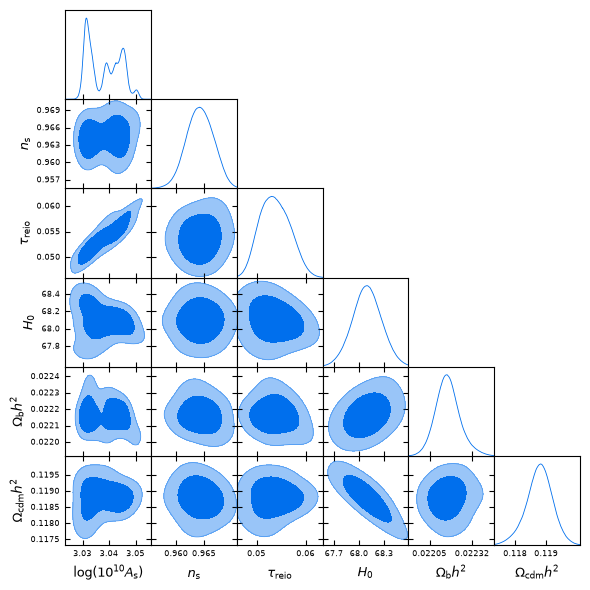

In [3]:
root = "../input/results/lcdm_full"

# Cargar las cuatro cadenas
samples = loadMCSamples(
    root,
    settings={"ignore_rows": 0.3}
)
print(samples.getTable().tableTex())

g = plots.get_subplot_plotter(width_inch=6)

g.triangle_plot(
    [samples],
    ["logA",
    "n_s",
    "tau_reio",
    "H0",
    "omega_b",
    "omega_cdm",],
    filled=True
)

plt.show()

In [4]:
import numpy as np
import glob
import os

# ============================================================
# Directorio de las cadenas MCMC
# ============================================================

root = "../input/results/lcdm_full"

chain_files = sorted(glob.glob(root + ".[0-9]*.txt"))

# ============================================================
# Contadores globales
# ============================================================
total_accepted = 0
total_rejected = 0
total_steps = 0
print("=" * 75)
print("MCMC SAMPLING STATISTICS")
print("=" * 75)

for file in chain_files:
    data = np.loadtxt(file, comments="#", ndmin=2)
    weights = data[:, 0]
    # Estados distintos almacenados
    n_accepted = len(weights)
    # Estados recorridos, incluyendo repeticiones
    n_steps = int(round(np.sum(weights)))
    # Rechazos inferidos de las repeticiones
    n_rejected = n_steps - n_accepted
    acceptance_rate = n_accepted / n_steps

    # Acumular
    total_accepted += n_accepted
    total_rejected += n_rejected
    total_steps += n_steps

    print(f"\nCadena: {os.path.basename(file)}")
    print(f"  Estados almacenados : {n_accepted}")
    print(f"  Rechazos inferidos   : {n_rejected}")
    print(f"  Pasos representados  : {n_steps}")
    print(f"  Fracción de cambios  : {acceptance_rate:.4f}")

# ============================================================
# Resumen global
# ============================================================

print("\n" + "=" * 75)
print("COBAYA MCMC SUMMARY")
print("=" * 75)

print(f"Estados almacenados : {total_accepted}")
print(f"Rechazos inferidos   : {total_rejected}")
print(f"Pasos representados  : {total_steps}")

print(
    f"Cobaya acceptance rate  : "
    f"{total_accepted / total_steps:.4f}"
)

MCMC SAMPLING STATISTICS

Cadena: lcdm_full.1.txt
  Estados almacenados : 1000
  Rechazos inferidos   : 1087
  Pasos representados  : 2087
  Fracción de cambios  : 0.4792

Cadena: lcdm_full.2.txt
  Estados almacenados : 1000
  Rechazos inferidos   : 953
  Pasos representados  : 1953
  Fracción de cambios  : 0.5120

Cadena: lcdm_full.3.txt
  Estados almacenados : 1000
  Rechazos inferidos   : 976
  Pasos representados  : 1976
  Fracción de cambios  : 0.5061

Cadena: lcdm_full.4.txt
  Estados almacenados : 1000
  Rechazos inferidos   : 896
  Pasos representados  : 1896
  Fracción de cambios  : 0.5274

COBAYA MCMC SUMMARY
Estados almacenados : 4000
Rechazos inferidos   : 3912
Pasos representados  : 7912
Cobaya acceptance rate  : 0.5056


In [6]:
import sys
import os
# Debe definirse antes de importar JAX/BOBE
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count={}".format(
    os.cpu_count()
)    
print(sys.executable)

/Users/johnatanroman/anaconda3/envs/bobe/bin/python


In [5]:
import BOBE
import cobaya
import classy
import jax

print("Todo correctamente instalado.")
print("Backend:", jax.default_backend())
print("Número de dispositivos JAX:", jax.device_count())

for i, device in enumerate(jax.devices()):
    print(i, device)

INFO:2026-10-22 00:00:53,881:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/johnatanroman/anaconda3/envs/bobe/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file)


[0: jax._src.xla_bridge] INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/johnatanroman/anaconda3/envs/bobe/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file)
[0: bo] INFO: JAX using 1 devices.
Todo correctamente instalado.
Backend: cpu
Número de dispositivos JAX: 1
0 TFRT_CPU_0


In [6]:
#############################################################
# Configuración inicial de BOBE
#############################################################

import os
import time
from BOBE import BOBE

run_name = "lcdm_full_test_00"

yaml_file = "/Users/johnatanroman/bobe_workshop/input/lcdm_full.yaml"

results_dir = f"/Users/johnatanroman/bobe_workshop/results/{run_name}/"
os.makedirs(results_dir, exist_ok=True)

print(f"Corrida: {run_name}")
print(f"YAML:    {yaml_file}")
print(f"Salida:  {results_dir}")

print("Inicializando BOBE...")
start = time.time()

bobe = BOBE(
    loglikelihood=yaml_file,
    likelihood_name=run_name,

    n_cobaya_init=8,
    n_sobol_init=32,

    optimizer="scipy",
    gp_kwargs={
        "lengthscale_prior": None,
        "lengthscale_bounds": [1e-2, 4.]
    },

    use_clf=True,
    clf_type="svm",

    save=False,
    save_dir=results_dir,

    # Nueva corrida
    resume=False,

    verbosity="INFO",
    seed=42,
)

print("BOBE inicializado correctamente.")

#############################################################
# Verificar dimensionalidad
#############################################################

print("\nNúmero de parámetros que BOBE va a muestrear:")
print(bobe.ndim)

print("\nLista de parámetros:")
for i, p in enumerate(bobe.loglikelihood.param_list, 1):
    print(f"{i:2d}. {p}")

[0: model] WARNING: Ignored blocks/options: ['sampler', 'output', 'force']


Corrida: lcdm_full_test_00
YAML:    /Users/johnatanroman/bobe_workshop/input/lcdm_full.yaml
Salida:  /Users/johnatanroman/bobe_workshop/results/lcdm_full_test_00/
Inicializando BOBE...
[0: classy] INFO: `classy` module loaded successfully from /Users/johnatanroman/anaconda3/envs/bobe/lib/python3.11/site-packages/classy
[0: planck_npipe_highl_camspec.ttteee] INFO: L-range for 143x143: 30 2000
[0: planck_npipe_highl_camspec.ttteee] INFO: L-range for 217x217: 500 2500
[0: planck_npipe_highl_camspec.ttteee] INFO: L-range for 143x217: 500 2500
[0: planck_npipe_highl_camspec.ttteee] INFO: L-range for TE: 30 2000
[0: planck_npipe_highl_camspec.ttteee] INFO: L-range for EE: 30 2000
[0: planck_npipe_highl_camspec.ttteee] INFO: Number of data points: 9915
[0: bao.desi_dr2] INFO: Initialized.


[0: prior] WARNING: There are unbounded parameters (['calTE', 'A_planck', 'calEE']). Prior bounds are given at 0.9999995 confidence level. Beware of likelihood modes at the edge of the prior


[0: likelihood] INFO: Initialized lcdm_full_test_00 with 15 params
[0: likelihood] INFO: Param list: ['logA', 'n_s', 'tau_reio', 'H0', 'omega_b', 'omega_cdm', 'A_planck', 'amp_143', 'amp_217', 'amp_143x217', 'n_143', 'n_217', 'n_143x217', 'calTE', 'calEE']
[0: likelihood] INFO: Param bounds: {'logA': [2.98, 3.1], 'n_s': [0.94, 0.99], 'tau_reio': [0.03, 0.08], 'H0': [64, 72], 'omega_b': [0.021, 0.023], 'omega_cdm': [0.11, 0.13], 'A_planck': [0.987434, 1.01257], 'amp_143': [0, 50], 'amp_217': [0, 50], 'amp_143x217': [0, 50], 'n_143': [0, 5], 'n_217': [0, 5], 'n_143x217': [0, 5], 'calTE': [0.949737, 1.05026], 'calEE': [0.949737, 1.05026]}
[0: likelihood] INFO: Logprior volume = -7.8728
[0: seed_utils] INFO: Global random seed set to 42
[0: results] INFO: Initialized BOBE results manager for 15D problem
[0: bo] INFO: Evaluating 32 Sobol initial points
[0: bo] INFO: Hyperparameters before refit: {'lengthscales': {'logA': '1.0000', 'n_s': '1.0000', 'tau_reio': '1.0000', 'H0': '1.0000', 'omeg

In [7]:
#############################################################
# Configuración inicial de BOBE
#############################################################

import os
import time
from BOBE import BOBE

# Nombre de esta corrida
run_name = "lcdm_full_test_00"

# Archivo YAML de Cobaya
yaml_file = "/Users/johnatanroman/bobe_workshop/input/lcdm_full.yaml"

# Directorio de resultados
results_dir = f"/Users/johnatanroman/bobe_workshop/results/{run_name}/"
os.makedirs(results_dir, exist_ok=True) #Crear directorio antes de inicializar BOBE

print(f"Corrida: {run_name}")
print(f"YAML:    {yaml_file}")
print(f"Salida:  {results_dir}")

print("Inicializando BOBE...")
start = time.time()

bobe = BOBE(
    loglikelihood = yaml_file,
    likelihood_name = run_name,
    
    # Para priors gaussianos no acotados:
    # A_planck, calTE y calEE
    confidence_for_unbounded=0.9999995, 
    
    # Puntos iniciales con los que aprende el GP
    n_cobaya_init=8,
    n_sobol_init=32,
    
    # Optimizador utilizado para ajustar los hiperparámetros del GP.
    optimizer='scipy',
    # Límites permitidos para las lengthscales.
    gp_kwargs={"lengthscale_prior": None, "lengthscale_bounds":[1e-2,4.]},
    
    # Clasificador, útil cuando el likelihood o el prior puede devolver -inf values
    use_clf=True,
    # Clasificador basado en Support Vector Machines.
    clf_type="svm",

    # Guardado 
    save = True,
    save_dir = results_dir,
    
    # Primera corrida
    resume=False,

    # Para continuar posteriormente:
    #resume=True,
    #resume_file=os.path.join(results_dir, run_name),
    
    
    # Cuanta información muestra
    verbosity="INFO",
    seed=42, #Semilla aleatoria de generación
)

print("BOBE inicializado correctamente.")

#############################################################
# Ejecutar BOBE
#############################################################
results = bobe.run(
    # WIPStd: Weighted Integrated Posterior Standard Deviation.
    # Selecciona nuevos puntos de evaluación utilizando
    # información del GP para reducir la incertidumbre
    # relevante para la inferencia bayesiana.
    acq="wipstd", #función de adquisición
    
    #Número de evaluaciones
    min_evals=70,
    max_evals=500,
    
    #Gaussian Process
    max_gp_size=500, # Usado para entrenar GP
    # Frecuencia de reajuste de hiperparámetros del GP, expresada en nuevos puntos de entrenamiento.
    fit_n_points=10, # Número de candidatos/puntos usados en el ajuste
       
    # Número de puntos nuevos seleccionados por lote.
    # En cada iteración WIPStd se proponen hasta 5 puntos
    # para evaluar la función objetivo.
    batch_size=5,
    
    #Muestreo HMC/NUTS del emulador
    # Pasos de adaptación (warmup) por cadena.
    num_hmc_warmup=512,
    # Muestras posteriores solicitadas por cadena.
    num_hmc_samples=4096,
    # Número de cadenas de muestreo.
    num_chains=4,
    # Estimaciones Monte Carlo
    # Número de puntos Monte Carlo utilizados en las estimaciones internas que requieren integración.
    mc_points_size=512,
    
    # Parámetro que controla el muestreo Nested Sampling utilizado por BOBE.
    ns_n_points=10,
    do_final_ns=True,
    
    #Criterio de convergencia
    convergence_n_iters=2, #número de iteraciones consecutivas necesarias para declarar convergencia
    logz_threshold=1.0, # Umbral de incertidumbre de evidencia utilizado por el criterio interno de BOBE.
)
end = time.time()
print(f"Tiempo total: {(end-start)/60:.2f} min")

[0: model] WARNING: Ignored blocks/options: ['sampler', 'output', 'force']


Corrida: lcdm_full_test_00
YAML:    /Users/johnatanroman/bobe_workshop/input/lcdm_full.yaml
Salida:  /Users/johnatanroman/bobe_workshop/results/lcdm_full_test_00/
Inicializando BOBE...
[0: classy] INFO: `classy` module loaded successfully from /Users/johnatanroman/anaconda3/envs/bobe/lib/python3.11/site-packages/classy
[0: planck_npipe_highl_camspec.ttteee] INFO: L-range for 143x143: 30 2000
[0: planck_npipe_highl_camspec.ttteee] INFO: L-range for 217x217: 500 2500
[0: planck_npipe_highl_camspec.ttteee] INFO: L-range for 143x217: 500 2500
[0: planck_npipe_highl_camspec.ttteee] INFO: L-range for TE: 30 2000
[0: planck_npipe_highl_camspec.ttteee] INFO: L-range for EE: 30 2000
[0: planck_npipe_highl_camspec.ttteee] INFO: Number of data points: 9915
[0: bao.desi_dr2] INFO: Initialized.


[0: prior] WARNING: There are unbounded parameters (['calTE', 'A_planck', 'calEE']). Prior bounds are given at 0.9999995 confidence level. Beware of likelihood modes at the edge of the prior


[0: likelihood] INFO: Initialized lcdm_full_test_00 with 15 params
[0: likelihood] INFO: Param list: ['logA', 'n_s', 'tau_reio', 'H0', 'omega_b', 'omega_cdm', 'A_planck', 'amp_143', 'amp_217', 'amp_143x217', 'n_143', 'n_217', 'n_143x217', 'calTE', 'calEE']
[0: likelihood] INFO: Param bounds: {'logA': [2.98, 3.1], 'n_s': [0.94, 0.99], 'tau_reio': [0.03, 0.08], 'H0': [64, 72], 'omega_b': [0.021, 0.023], 'omega_cdm': [0.11, 0.13], 'A_planck': [0.987434, 1.01257], 'amp_143': [0, 50], 'amp_217': [0, 50], 'amp_143x217': [0, 50], 'n_143': [0, 5], 'n_217': [0, 5], 'n_143x217': [0, 5], 'calTE': [0.949737, 1.05026], 'calEE': [0.949737, 1.05026]}
[0: likelihood] INFO: Logprior volume = -7.8728
[0: seed_utils] INFO: Global random seed set to 42
[0: results] INFO: Initialized BOBE results manager for 15D problem
[0: bo] INFO: Evaluating 32 Sobol initial points
[0: bo] INFO: Hyperparameters before refit: {'lengthscales': {'logA': '1.0000', 'n_s': '1.0000', 'tau_reio': '1.0000', 'H0': '1.0000', 'omeg

In [15]:
import numpy as np
from getdist import MCSamples, plots
import matplotlib.pyplot as plt
from getdist import loadMCSamples

import json
from pathlib import Path

In [9]:
import os
import pickle

run_name = "lcdm_full_test_00"

results_dir = f"/Users/johnatanroman/bobe_workshop/results/{run_name}/"

results_file = os.path.join(
    results_dir,
    f"{run_name}_results.pkl"
)

with open(results_file, "rb") as f:
    results = pickle.load(f)

print("Resultados cargados correctamente.")

Resultados cargados correctamente.


In [10]:
results.keys()

dict_keys(['samples', 'weights', 'logl', 'logwt', 'logz', 'logzerr', 'dlogz_sampler', 'final_logz_dict', 'logz_history', 'param_names', 'param_labels', 'param_bounds', 'ndim', 'n_samples', 'n_effective', 'converged', 'termination_reason', 'convergence_history', 'gp_info', 'acquisition_data', 'gp_hyperparams', 'best_loglike_data', 'kl_data', 'timing', 'run_info'])

In [11]:
# ============================================================
# Extraer resultados finales de BOBE
# ============================================================

# ------------------------------------------------------------
# Resultados principales
# ------------------------------------------------------------
samples = results["samples"]
logz    = results["logz"]

# Parámetros
param_bounds = results["param_bounds"]
param_list   = results["param_names"]
param_labels = results["param_labels"]

ndim = results["ndim"]

# ------------------------------------------------------------
# Mejor log-likelihood
# ------------------------------------------------------------
# Mejor punto encontrado por Nested Sampling
best_logl_ns = np.max(results["logl"])

# Mejor punto encontrado durante la optimización de BOBE
best_logl_bo = np.max(
    np.asarray(
        results["best_loglike_data"]["best_loglike"],
        dtype=float
    )
)

delta_logl = best_logl_ns - best_logl_bo

# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

print("=" * 60)
print("RESUMEN FINAL: LCDM_art_01")
print("=" * 60)

print(f"Dimensionalidad : {ndim}")
print(f"Best logL (BO)  : {best_logl_bo:.6f}")
print(f"Best logL (NS)  : {best_logl_ns:.6f}")
print(f"ΔlogL NS-BO     : {delta_logl:.6f}")
print(f"Termination     : {results['termination_reason']}")

print("\nParámetros:")
for i, p in enumerate(param_list, 1):
    print(f"{i:2d}. {p}")

RESUMEN FINAL: LCDM_art_01
Dimensionalidad : 15
Best logL (BO)  : -6308.049606
Best logL (NS)  : -5603.365317
ΔlogL NS-BO     : 704.684289
Termination     : Maximum evaluations reached

Parámetros:
 1. logA
 2. n_s
 3. tau_reio
 4. H0
 5. omega_b
 6. omega_cdm
 7. A_planck
 8. amp_143
 9. amp_217
10. amp_143x217
11. n_143
12. n_217
13. n_143x217
14. calTE
15. calEE


In [12]:
print("logz:", results["logz"])
print("logzerr:", results["logzerr"])
print("dlogz_sampler:", results["dlogz_sampler"])
print("\nfinal_logz_dict:")
print(results["final_logz_dict"])

logz: -5661.961685480441
logzerr: 16.608602509593744
dlogz_sampler: 0.2959514938925831

final_logz_dict:
{'mean': np.float64(-5661.961685480441), 'dlogz_sampler': np.float64(0.2959514938925831), 'upper': np.float64(-4906.349978610928), 'lower': np.float64(-6255.179172014316), 'var': np.float64(68.96141933042091), 'std': np.float64(16.608602509593744)}


In [13]:
# ============================================================
# Evidencia Bayesiana
# ============================================================

logz_final = results["final_logz_dict"]

# Valor central
lnZ = float(results["logz"])

# Incertidumbres
sigma_integrator = float(results["dlogz_sampler"])
sigma_emulator   = float(results["logzerr"])

# Límites de BOBE
lnZ_lower = float(logz_final["lower"])
lnZ_upper = float(logz_final["upper"])

# ============================================================
# Resumen
# ============================================================

print("\n" + "=" * 60)
print("BAYESIAN EVIDENCE")
print("=" * 60)

print(f"ln Z              = {lnZ:.6f}")
print(f"Integrator error  = {sigma_integrator:.6f}")
print(f"Emulator error    = {sigma_emulator:.6f}")

print(f"\nlower             = {lnZ_lower:.6f}")
print(f"upper             = {lnZ_upper:.6f}")

print(
    "\nln Z = "
    f"{lnZ:.4f} "
    f"± {sigma_integrator:.4f} (integrator) "
    f"± {sigma_emulator:.4f} (emulator)"
)


BAYESIAN EVIDENCE
ln Z              = -5661.961685
Integrator error  = 0.295951
Emulator error    = 16.608603

lower             = -6255.179172
upper             = -4906.349979

ln Z = -5661.9617 ± 0.2960 (integrator) ± 16.6086 (emulator)


In [14]:
# ============================================================
# Tiempos de ejecución por fase — BOBE
# ============================================================
timing = results["timing"]
phase_times = timing["phase_times"]
percentages = timing["percentages"]
total_time = sum(phase_times.values())
print("\n" + "=" * 70)
print(f"PHASE TIMES — {run_name}")
print("=" * 70)

# Tiempo por fase
for phase, t in phase_times.items():
    print(
        f"{phase:25s}: "
        f"{t:10.2f} s = "
        f"{t/60:7.3f} min = "
        f"{t/3600:7.3f} h "
        f"({percentages.get(phase, 0):5.1f}%)"
    )

# Total
print("-" * 70)

print(
    f"{'TOTAL':25s}: "
    f"{total_time:10.2f} s = "
    f"{total_time/60:7.3f} min = "
    f"{total_time/3600:7.3f} h "
    f"(100.0%)"
)


PHASE TIMES — lcdm_full_test_00
GP Training              :      55.11 s =   0.919 min =   0.015 h (  5.2%)
Acquisition Optimization :     452.49 s =   7.542 min =   0.126 h ( 42.9%)
True Objective Evaluations:     254.97 s =   4.249 min =   0.071 h ( 24.1%)
Nested Sampling          :      46.69 s =   0.778 min =   0.013 h (  4.4%)
MCMC Sampling            :     220.95 s =   3.683 min =   0.061 h ( 20.9%)
Classifier Training      :       3.42 s =   0.057 min =   0.001 h (  0.3%)
----------------------------------------------------------------------
TOTAL                    :    1033.64 s =  17.227 min =   0.287 h (100.0%)


In [25]:
# ============================================================
# Construir MCSamples correctamente desde results.pkl
# ============================================================
from getdist import MCSamples

samples_array = np.asarray(results["samples"])
weights_array = np.asarray(results["weights"])

param_names  = list(results["param_names"])
param_labels = list(results["param_labels"])
param_bounds = np.asarray(results["param_bounds"])

# Asegurar formato (ndim, 2)
if param_bounds.shape == (2, len(param_names)):
    param_bounds = param_bounds.T

# Límites de los parámetros
ranges = {
    name: [float(bounds[0]), float(bounds[1])]
    for name, bounds in zip(param_names, param_bounds)
}

samples_lcdm = MCSamples(
    samples=samples_array,
    weights=weights_array,
    names=param_names,
    labels=param_labels,
    ranges=ranges,
    label="LCDM_full"
)

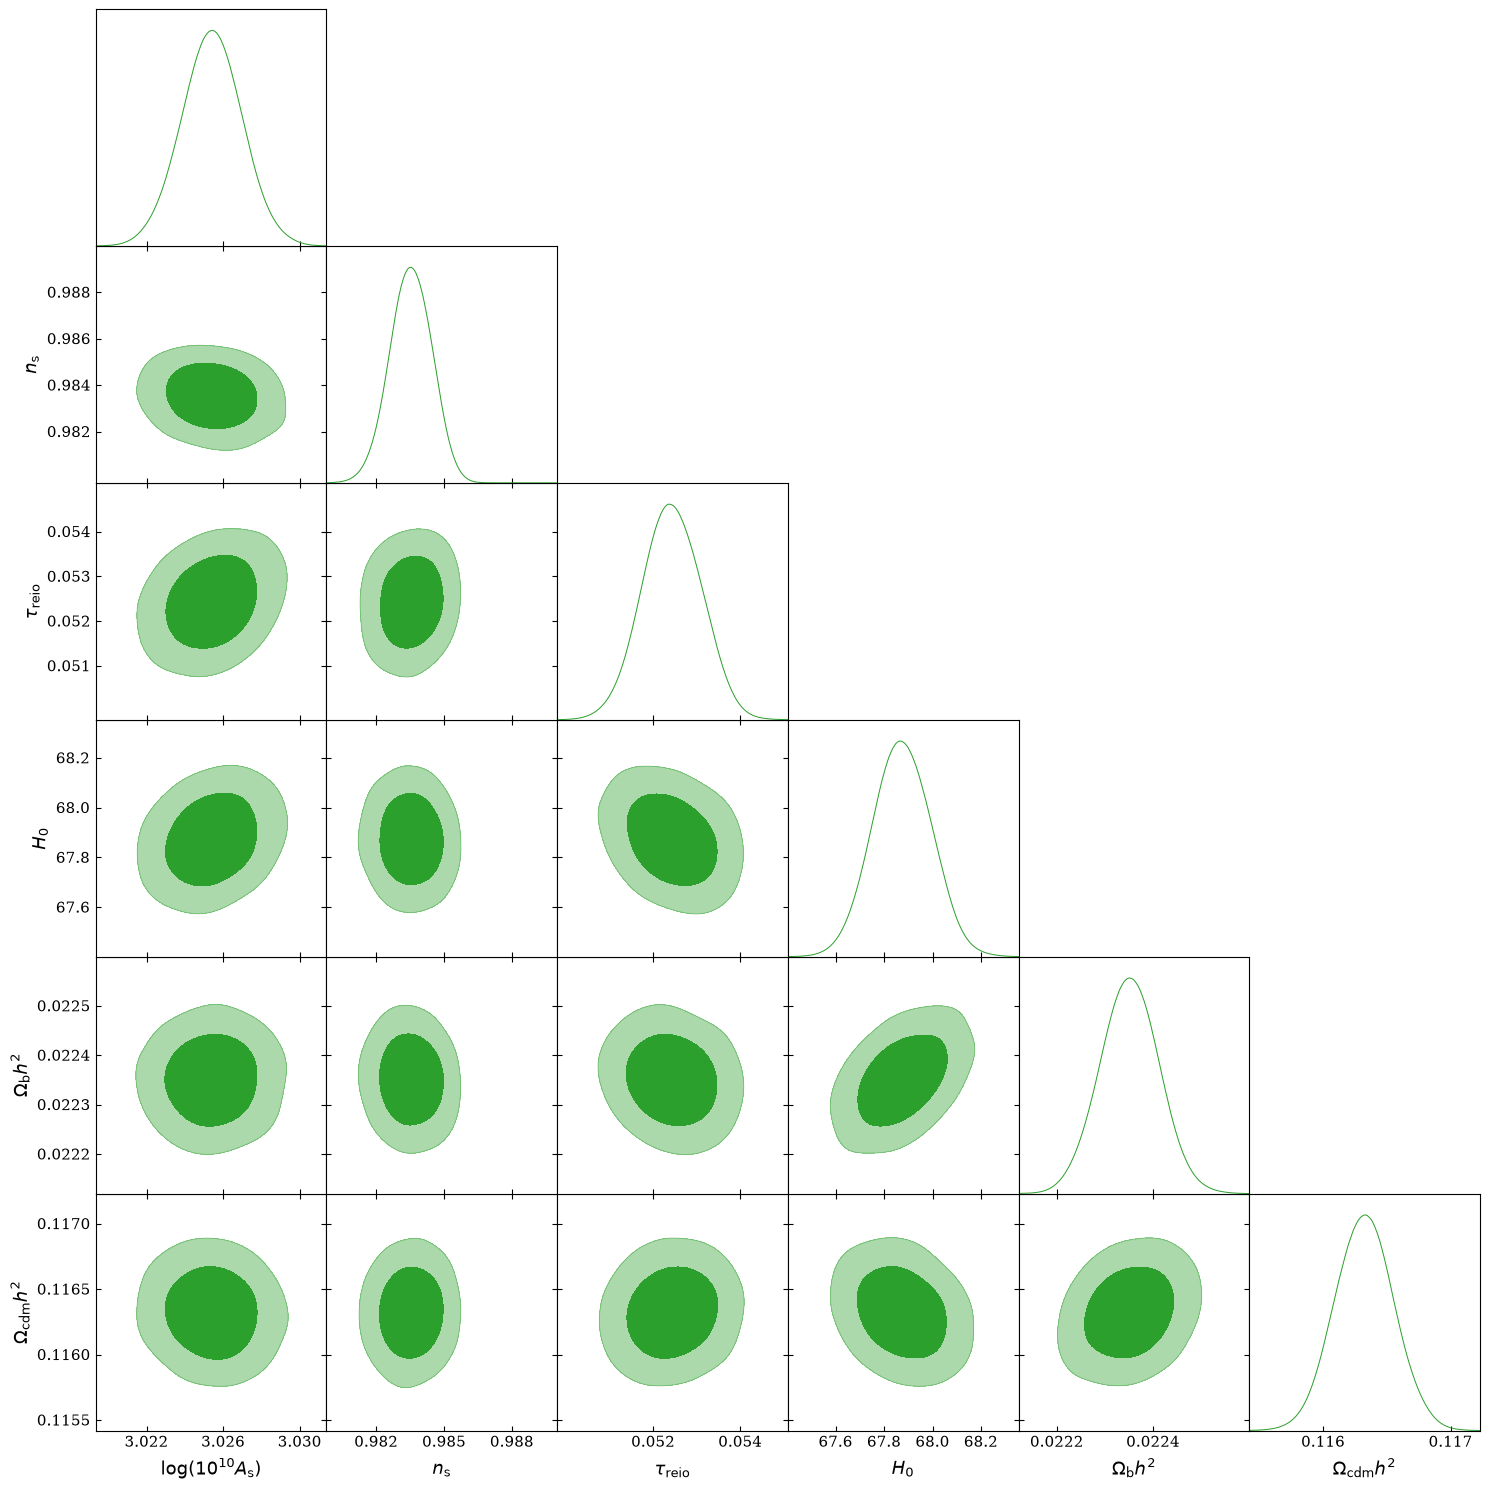

In [26]:
# ============================================================
# Triangle plot: parámetros cosmológicos
# ============================================================
params_cosmo = [
    "logA",
    "n_s",
    "tau_reio",
    "H0",
    "omega_b",
    "omega_cdm",
]

g = plots.get_subplot_plotter(
    subplot_size=2.5,
    subplot_size_ratio=1
)

g.settings.legend_fontsize = 14
g.settings.axes_fontsize = 13
g.settings.axes_labelsize = 15

g.triangle_plot(
    samples_lcdm,
    params_cosmo,
    filled=True,
    contour_colors=["C2"]
)

In [27]:
# ============================================================
# Cargar estado guardado del GP
# ============================================================
gp_file = os.path.join(
    results_dir,
    f"{run_name}_gp.npz"
)

gp_data = np.load(
    gp_file,
    allow_pickle=True
)

print(gp_data.files)

['train_x', 'train_y', 'lengthscales', 'kernel_variance', 'noise', 'tausq', 'y_mean', 'y_std', 'kernel_name', 'lengthscale_prior_spec', 'kernel_variance_prior_spec', 'fixed_kernel_variance', 'optimizer_method', 'optimizer_options', 'lengthscale_bounds', 'kernel_variance_bounds', 'tausq_bounds', 'cholesky', 'alphas', 'ndim', 'gp_class', 'train_x_clf', 'train_y_clf', 'clf_type', 'clf_settings', 'clf_use_size', 'clf_update_step', 'probability_threshold', 'minus_inf', 'clf_threshold', 'gp_threshold', 'use_clf', 'clf_params', 'clf_metrics']


GP training points: 406


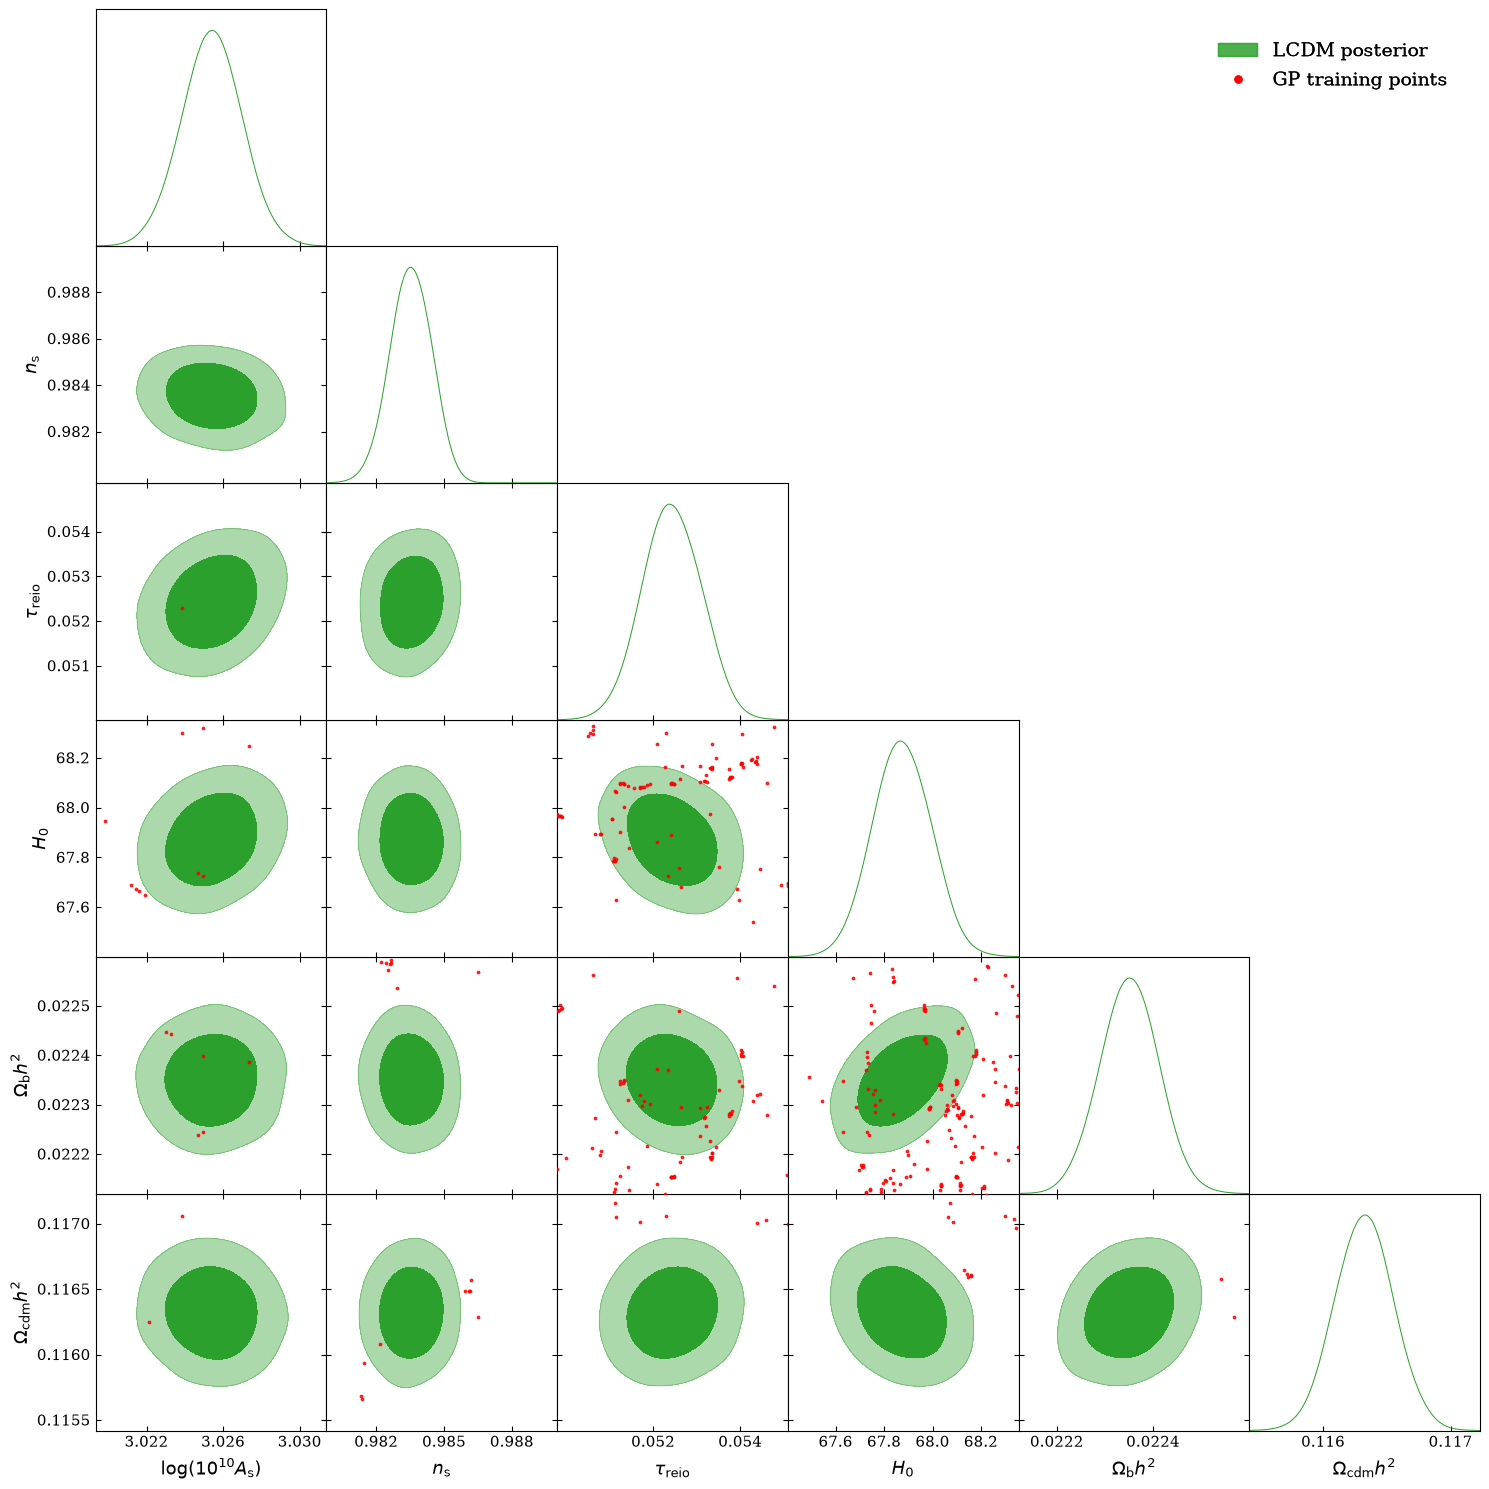

In [28]:
# ============================================================
# Triangle plot + GP training points
# ============================================================
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
# ------------------------------------------------------------
# Training points del GP
# ------------------------------------------------------------
train_x = np.asarray(gp_data["train_x"])
# Escalar:
# coordenadas normalizadas del GP -> parámetros físicos
lower = param_bounds[:, 0]
upper = param_bounds[:, 1]
training_points = (lower+ train_x * (upper - lower))
print("GP training points:", training_points.shape[0])
# ============================================================
# Parámetros que queremos mostrar
# ============================================================

# Índices de estos parámetros dentro del GP
param_indices = [
    param_names.index(par)
    for par in params_cosmo
]
# ============================================================
# Triangle plot
# ============================================================
g = plots.get_subplot_plotter(subplot_size=2.5, subplot_size_ratio=1)
g.settings.legend_fontsize = 14
g.settings.axes_fontsize = 13
g.settings.axes_labelsize = 15
# Posterior final
g.triangle_plot(samples_lcdm, params_cosmo, filled=True, contour_colors=["C2"])
# ============================================================
# Superponer GP training points
# ============================================================
npar = len(params_cosmo)
for i in range(npar):
    for j in range(i + 1, npar):
        ax = g.subplots[j, i]
        idx_x = param_indices[i]
        idx_y = param_indices[j]
        ax.scatter(
            training_points[:, idx_x],
            training_points[:, idx_y],
            color="red",
            s=3,
            alpha=0.80,
            rasterized=True, #False
            zorder=10
        )
# ============================================================
# Leyenda
# ============================================================
legend_handles = [
    Patch(
        facecolor="C2",
        edgecolor="C2",
        alpha=0.6,
        label=r"LCDM posterior"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="red",
        markeredgecolor="red",
        markersize=5,
        label="GP training points"
    )
]
g.fig.legend(
    handles=legend_handles,
    loc="upper right",
    bbox_to_anchor=(0.98, 0.98),
    frameon=False,
    fontsize=14
)
g.fig.legend(handles=legend_handles, loc="upper right", bbox_to_anchor=(0.98, 0.98), frameon=False, fontsize=14) #False
plt.show()